<a href="https://colab.research.google.com/github/EconUttam/Credit-Risk-Classification-via-Logistic-Regression/blob/main/Credit_Risk_Modelling_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import files

uploaded = files.upload()

Saving south+german+credit.zip to south+german+credit.zip


In [2]:

import zipfile
import os

# Find the ZIP file you uploaded
zip_name = next(
    name for name in uploaded
    if name.lower().endswith(".zip")
)

with zipfile.ZipFile(zip_name, "r") as z:
    print("Files found inside ZIP:")
    for name in z.namelist():
        print(name)

    z.extractall("/content/credit_data")

print("\nExtraction complete!")
print("Extracted files:")

for root, dirs, filenames in os.walk("/content/credit_data"):
    for name in filenames:
        print(os.path.join(root, name))


Files found inside ZIP:
codetable.txt
read_SouthGermanCredit.R
SouthGermanCredit.asc

Extraction complete!
Extracted files:
/content/credit_data/SouthGermanCredit.asc
/content/credit_data/codetable.txt
/content/credit_data/read_SouthGermanCredit.R


In [3]:

import pandas as pd
import os

data_path = "/content/credit_data/SouthGermanCredit.asc"

# Read the whitespace-separated dataset
df = pd.read_csv(data_path, sep=r"\s+")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five observations:")
display(df.head())

print("\nMissing values in the dataset:")
print(df.isnull().sum().sum())


Dataset loaded successfully!
Number of rows: 1000
Number of columns: 21

Column names:
['laufkont', 'laufzeit', 'moral', 'verw', 'hoehe', 'sparkont', 'beszeit', 'rate', 'famges', 'buerge', 'wohnzeit', 'verm', 'alter', 'weitkred', 'wohn', 'bishkred', 'beruf', 'pers', 'telef', 'gastarb', 'kredit']

First five observations:


,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1



Missing values in the dataset:
0


In [ ]:

# Display the dataset codebook
codebook_path = "/content/credit_data/codetable.txt"

with open(codebook_path, "r", encoding="utf-8", errors="replace") as f:
    print(f.read())

# Inspect the target variable
print("\nCredit-risk outcome column:")
print(df["kredit"].value_counts().sort_index())

print("\nUnique target values:")
print(sorted(df["kredit"].unique()))

# Check all column names without truncation
print("\nAll 21 column names:")
for i, col in enumerate(df.columns, start=1):
    print(i, col)


$`laufkont = status`
                                               
 1 : no checking account                       
 2 : ... < 0 DM                                
 3 : 0<= ... < 200 DM                          
 4 : ... >= 200 DM / salary for at least 1 year

$`laufzeit = duration`
     

$`moral = credit_history`
                                                
 0 : delay in paying off in the past            
 1 : critical account/other credits elsewhere   
 2 : no credits taken/all credits paid back duly
 3 : existing credits paid back duly till now   
 4 : all credits at this bank paid back duly    

$`verw = purpose`
                        
 0 : others             
 1 : car (new)          
 2 : car (used)         
 3 : furniture/equipment
 4 : radio/television   
 5 : domestic appliances
 6 : repairs            
 7 : education          
 8 : vacation           
 9 : retraining         
 10 : business          

$`hoehe = amount`
     

$`sparkont = savings`
                     

In [4]:

# STEP 5: Prepare the modelling dataset

import pandas as pd

# Create a new binary target
df["default_risk"] = (df["kredit"] == 0).astype(int)

# Select six explanatory variables
features = [
    "laufzeit",
    "hoehe",
    "alter",
    "moral",
    "sparkont",
    "beszeit"
]

# Create a separate modelling dataframe
model_df = df[features + ["default_risk"]].copy()

# Rename variables for readability
model_df = model_df.rename(columns={
    "laufzeit": "loan_duration",
    "hoehe": "credit_amount",
    "alter": "age",
    "moral": "credit_history",
    "sparkont": "savings_status",
    "beszeit": "employment_duration"
})

# Convert categorical codes to categorical types
categorical_cols = [
    "credit_history",
    "savings_status",
    "employment_duration"
]

for col in categorical_cols:
    model_df[col] = model_df[col].astype("category")

# Verify the resulting dataset
print("Modelling dataset shape:", model_df.shape)

print("\nFirst five observations:")
display(model_df.head())

print("\nVariable types:")
print(model_df.dtypes)

print("\nOutcome distribution:")
print(model_df["default_risk"].value_counts())

print("\nMissing values:")
print(model_df.isnull().sum())


Modelling dataset shape: (1000, 7)

First five observations:


,loan_duration,credit_amount,age,credit_history,savings_status,employment_duration,default_risk
0,18,1049,21,4,1,2,0
1,9,2799,36,4,1,3,0
2,12,841,23,2,2,4,0
3,12,2122,39,4,1,3,0
4,12,2171,38,4,1,3,0



Variable types:
loan_duration             int64
credit_amount             int64
age                       int64
credit_history         category
savings_status         category
employment_duration    category
default_risk              int64
dtype: object

Outcome distribution:
default_risk
0    700
1    300
Name: count, dtype: int64

Missing values:
loan_duration          0
credit_amount          0
age                    0
credit_history         0
savings_status         0
employment_duration    0
default_risk           0
dtype: int64


A. DESCRIPTIVE STATISTICS


,loan_duration,credit_amount,age
count,1000.00,1000.00,1000.00
mean,20.90,3271.25,35.54
std,12.06,2822.75,11.35
min,4.00,250.00,19.00
25%,12.00,1365.50,27.00
50%,18.00,2319.50,33.00
75%,24.00,3972.25,42.00
max,72.00,18424.00,75.00



B. CREDIT-RISK DISTRIBUTION
0 = Good credit risk
1 = Bad credit risk
default_risk
0    700
1    300
Name: count, dtype: int64

Percentages:
default_risk
0    70.0
1    30.0
Name: count, dtype: float64


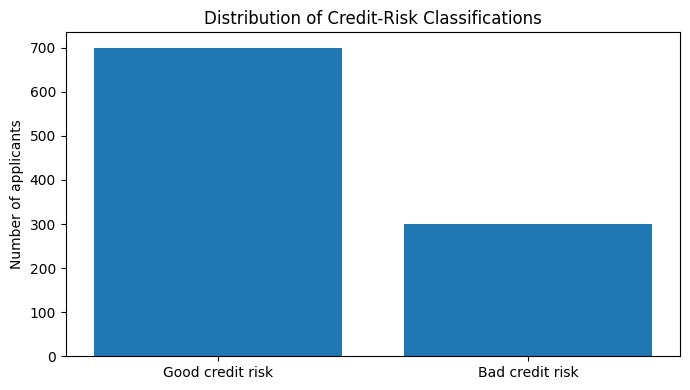

<Figure size 700x400 with 0 Axes>

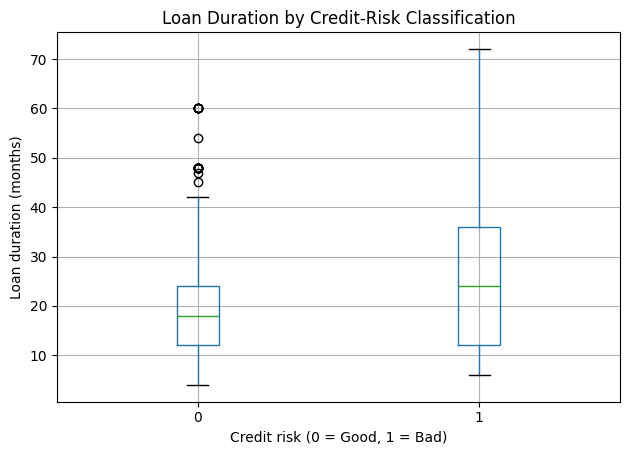

<Figure size 700x400 with 0 Axes>

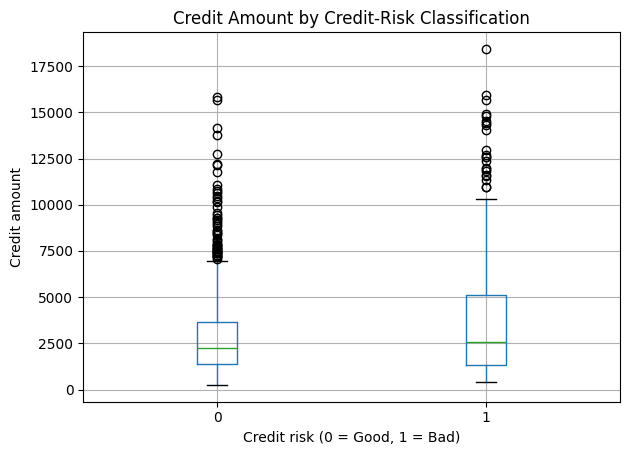


C. CREDIT HISTORY AND OBSERVED BAD-RISK RATE


,applicants,bad_risk_rate,bad_risk_rate_pct
credit_history,,,
0,40,0.625000,62.50
1,49,0.571429,57.14
2,530,0.318868,31.89
3,88,0.318182,31.82
4,293,0.170648,17.06


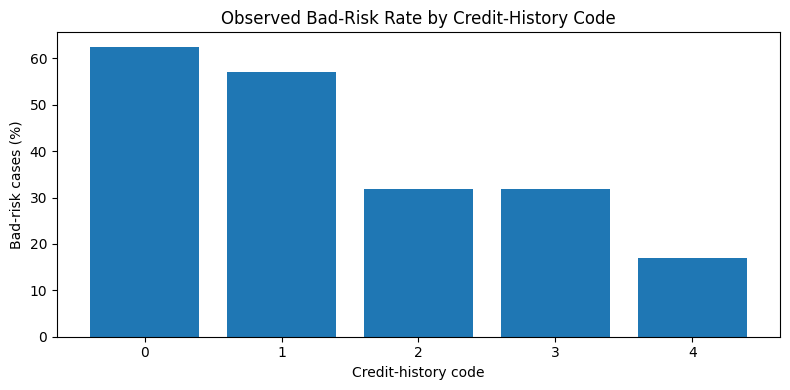

In [5]:

# STEP 6: Exploratory Data Analysis (EDA)

import pandas as pd
import matplotlib.pyplot as plt

# 1. Descriptive statistics
print("A. DESCRIPTIVE STATISTICS")
display(
    model_df[["loan_duration", "credit_amount", "age"]]
    .describe()
    .round(2)
)

# 2. Distribution of credit-risk outcomes
risk_counts = model_df["default_risk"].value_counts().sort_index()

print("\nB. CREDIT-RISK DISTRIBUTION")
print("0 = Good credit risk")
print("1 = Bad credit risk")
print(risk_counts)
print("\nPercentages:")
print((risk_counts / len(model_df) * 100).round(2))

plt.figure(figsize=(7, 4))
plt.bar(
    ["Good credit risk", "Bad credit risk"],
    [risk_counts.get(0, 0), risk_counts.get(1, 0)]
)
plt.title("Distribution of Credit-Risk Classifications")
plt.ylabel("Number of applicants")
plt.tight_layout()
plt.show()

# 3. Compare loan duration between risk groups
plt.figure(figsize=(7, 4))
model_df.boxplot(column="loan_duration", by="default_risk")
plt.title("Loan Duration by Credit-Risk Classification")
plt.suptitle("")
plt.xlabel("Credit risk (0 = Good, 1 = Bad)")
plt.ylabel("Loan duration (months)")
plt.tight_layout()
plt.show()

# 4. Compare credit amounts between risk groups
plt.figure(figsize=(7, 4))
model_df.boxplot(column="credit_amount", by="default_risk")
plt.title("Credit Amount by Credit-Risk Classification")
plt.suptitle("")
plt.xlabel("Credit risk (0 = Good, 1 = Bad)")
plt.ylabel("Credit amount")
plt.tight_layout()
plt.show()

# 5. Observed bad-risk proportions by credit-history code
history_summary = (
    model_df.groupby("credit_history", observed=False)
    .agg(
        applicants=("default_risk", "size"),
        bad_risk_rate=("default_risk", "mean")
    )
)

history_summary["bad_risk_rate_pct"] = (
    history_summary["bad_risk_rate"] * 100
).round(2)

print("\nC. CREDIT HISTORY AND OBSERVED BAD-RISK RATE")
display(history_summary)

plt.figure(figsize=(8, 4))
plt.bar(
    history_summary.index.astype(str),
    history_summary["bad_risk_rate_pct"]
)
plt.title("Observed Bad-Risk Rate by Credit-History Code")
plt.xlabel("Credit-history code")
plt.ylabel("Bad-risk cases (%)")
plt.tight_layout()
plt.show()


Training observations: 800
Test observations: 200

Training outcome proportions:
default_risk
0    0.7
1    0.3
Name: proportion, dtype: float64

Test outcome proportions:
default_risk
0    0.7
1    0.3
Name: proportion, dtype: float64

MODEL PERFORMANCE ON TEST DATA


,Metric,Value
0,Accuracy,0.730
1,Precision,0.607
2,Recall,0.283
3,F1-score,0.386
4,ROC-AUC,0.698



CLASSIFICATION REPORT
                  precision    recall  f1-score   support

Good credit risk       0.75      0.92      0.83       140
 Bad credit risk       0.61      0.28      0.39        60

        accuracy                           0.73       200
       macro avg       0.68      0.60      0.61       200
    weighted avg       0.71      0.73      0.69       200



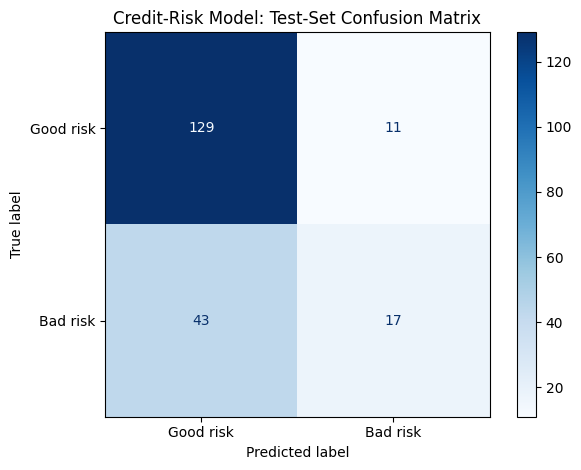

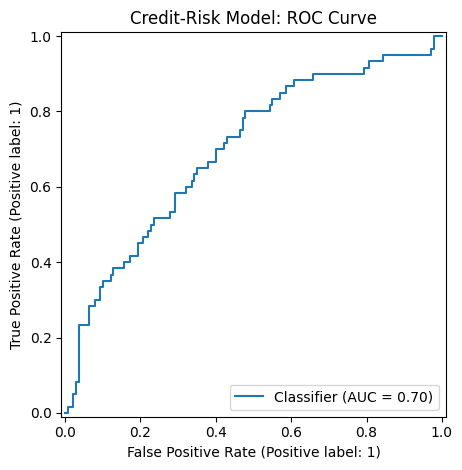

In [6]:

# STEP 8: Logistic Regression Credit-Risk Model

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# 1. Define predictors and target
X = model_df.drop(columns="default_risk")
y = model_df["default_risk"]

numeric_cols = [
    "loan_duration",
    "credit_amount",
    "age"
]

categorical_cols = [
    "credit_history",
    "savings_status",
    "employment_duration"
]

# 2. Split data BEFORE fitting preprocessing or the model
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

print("\nTraining outcome proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTest outcome proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

# 3. Prepare numerical and categorical variables
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_cols),
        (
            "categorical",
            OneHotEncoder(drop="first", handle_unknown="ignore"),
            categorical_cols
        )
    ]
)

# 4. Build a single reproducible modelling pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("logistic_regression", LogisticRegression(max_iter=2000))
])

# 5. Fit on training data only
model.fit(X_train, y_train)

# 6. Predict the held-out test data
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# 7. Calculate performance metrics
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Value": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ]
})

print("\nMODEL PERFORMANCE ON TEST DATA")
display(results.round(3))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Good credit risk", "Bad credit risk"],
    zero_division=0
))

# 8. Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Good risk", "Bad risk"]
).plot(cmap="Blues", values_format="d")

plt.title("Credit-Risk Model: Test-Set Confusion Matrix")
plt.tight_layout()
plt.show()

# 9. ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("Credit-Risk Model: ROC Curve")
plt.tight_layout()
plt.show()


In [ ]:

# STEP 9: Interpret logistic regression coefficients

import pandas as pd
import numpy as np

# Retrieve transformed feature names
preprocessor_fitted = model.named_steps["preprocessor"]
logistic_fitted = model.named_steps["logistic_regression"]

feature_names = preprocessor_fitted.get_feature_names_out()
coefficients = logistic_fitted.coef_[0]

coef_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Odds_Ratio": np.exp(coefficients)
})

# Sort by coefficient for easier interpretation
coef_table = coef_table.sort_values(
    "Coefficient",
    ascending=False
).reset_index(drop=True)

print("LOGISTIC REGRESSION COEFFICIENTS")
display(coef_table.round(3))

print("\nModel intercept:")
print(round(logistic_fitted.intercept_[0], 3))


LOGISTIC REGRESSION COEFFICIENTS


,Feature,Coefficient,Odds_Ratio
0,categorical__credit_history_1,0.670,1.954
1,numeric__loan_duration,0.429,1.535
2,numeric__credit_amount,0.125,1.133
3,categorical__employment_duration_2,-0.001,0.999
4,numeric__age,-0.078,0.925
5,categorical__savings_status_2,-0.288,0.750
6,categorical__employment_duration_3,-0.375,0.688
7,categorical__employment_duration_5,-0.422,0.656
8,categorical__credit_history_2,-0.437,0.646
9,categorical__credit_history_3,-0.721,0.486



Model intercept:
0.38


In [7]:

# STEP 10: Explore different classification thresholds

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50]

threshold_results = []

for threshold in thresholds:
    # Classify as bad risk when predicted probability
    # is at least the chosen threshold
    pred = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_bad_risk": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall_bad_risk": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1_bad_risk": f1_score(
            y_test, pred, zero_division=0
        ),
        "Applicants_flagged_bad": int(pred.sum())
    })

threshold_table = pd.DataFrame(threshold_results)

print("THRESHOLD COMPARISON")
display(threshold_table.round(3))


THRESHOLD COMPARISON


,Threshold,Accuracy,Precision_bad_risk,Recall_bad_risk,F1_bad_risk,Applicants_flagged_bad
0,0.30,0.645,0.438,0.650,0.523,89
1,0.35,0.690,0.484,0.517,0.500,64
2,0.40,0.690,0.481,0.417,0.446,52
3,0.45,0.725,0.568,0.350,0.433,37
4,0.50,0.730,0.607,0.283,0.386,28


In [8]:

# STEP 11: Statistical inference for logistic regression

import statsmodels.formula.api as smf
import numpy as np
import pandas as pd

# Use training observations only
inference_data = X_train.copy()
inference_data["default_risk"] = y_train

# Explicitly treat coded predictors as categorical
formula = (
    "default_risk ~ loan_duration + credit_amount + age"
    " + C(credit_history) + C(savings_status)"
    " + C(employment_duration)"
)

inference_model = smf.logit(
    formula=formula,
    data=inference_data
).fit(disp=False)

# Coefficients and confidence intervals
conf = inference_model.conf_int()

inference_table = pd.DataFrame({
    "Coefficient": inference_model.params,
    "Std_Error": inference_model.bse,
    "P_value": inference_model.pvalues,
    "Odds_Ratio": np.exp(inference_model.params),
    "OR_CI_Lower": np.exp(conf[0]),
    "OR_CI_Upper": np.exp(conf[1])
})

print("LOGISTIC REGRESSION: TRAINING-SAMPLE INFERENCE")
display(inference_table.round(4))

print("\nModel observations:", int(inference_model.nobs))
print("Pseudo R-squared:", round(inference_model.prsquared, 4))
print("Log-likelihood:", round(inference_model.llf, 3))


LOGISTIC REGRESSION: TRAINING-SAMPLE INFERENCE


,Coefficient,Std_Error,P_value,Odds_Ratio,OR_CI_Lower,OR_CI_Upper
Intercept,0.2067,0.6313,0.7434,1.2296,0.3567,4.2379
C(credit_history)[T.1],0.5276,0.5109,0.3017,1.6949,0.6227,4.6136
C(credit_history)[T.2],-0.6927,0.3929,0.0779,0.5002,0.2316,1.0805
C(credit_history)[T.3],-1.0345,0.4663,0.0265,0.3554,0.1425,0.8864
C(credit_history)[T.4],-1.6553,0.4268,0.0001,0.1910,0.0828,0.4410
C(savings_status)[T.2],-0.3524,0.2673,0.1874,0.7030,0.4163,1.1871
C(savings_status)[T.3],-1.2570,0.4244,0.0031,0.2845,0.1238,0.6537
C(savings_status)[T.4],-1.3953,0.5652,0.0136,0.2478,0.0818,0.7501
C(savings_status)[T.5],-1.3003,0.2654,0.0000,0.2725,0.1620,0.4583
C(employment_duration)[T.2],-0.1805,0.3780,0.6331,0.8349,0.3980,1.7515



Model observations: 800
Pseudo R-squared: 0.1427
Log-likelihood: -418.967


In [9]:

# STEP 12: Make the credit-amount effect easier to interpret

beta_amount = inference_model.params["credit_amount"]
ci_amount = inference_model.conf_int().loc["credit_amount"]

amount_interpretation = pd.DataFrame({
    "Measure": [
        "Odds ratio per 1 unit",
        "Odds ratio per 1,000 units",
        "95% CI lower, per 1,000 units",
        "95% CI upper, per 1,000 units",
        "P-value"
    ],
    "Value": [
        np.exp(beta_amount),
        np.exp(beta_amount * 1000),
        np.exp(ci_amount.iloc[0] * 1000),
        np.exp(ci_amount.iloc[1] * 1000),
        inference_model.pvalues["credit_amount"]
    ]
})

display(amount_interpretation.round(4))


,Measure,Value
0,Odds ratio per 1 unit,1.0000
1,"Odds ratio per 1,000 units",1.0413
2,"95% CI lower, per 1,000 units",0.9679
3,"95% CI upper, per 1,000 units",1.1202
4,P-value,0.2781


Selected threshold: 0.34
Validation precision: 0.529
Validation recall: 0.6

FINAL TEST RESULTS


,Metric,Value
0,Selected threshold,0.340
1,Test accuracy,0.670
2,Test precision (bad risk),0.456
3,Test recall (bad risk),0.517
4,Test F1 (bad risk),0.484
5,Test ROC-AUC,0.698


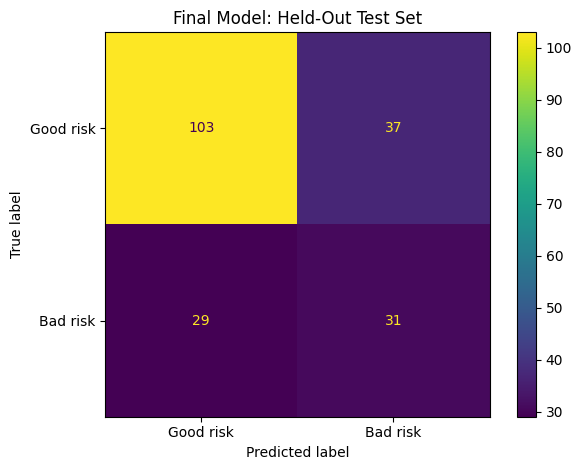

In [10]:

# STEP 13: Validation-based threshold selection and final evaluation

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Split the original training data into fitting and validation samples
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.25,
    random_state=123,
    stratify=y_train
)

# Fit a fresh copy of the existing modelling pipeline
validation_model = clone(model)
validation_model.fit(X_fit, y_fit)

# Choose threshold using validation data only
val_prob = validation_model.predict_proba(X_val)[:, 1]
thresholds = np.arange(0.20, 0.61, 0.01)

candidates = []

for threshold in thresholds:
    val_pred = (val_prob >= threshold).astype(int)
    recall = recall_score(y_val, val_pred, zero_division=0)
    precision = precision_score(y_val, val_pred, zero_division=0)

    if recall >= 0.50:
        candidates.append({
            "threshold": threshold,
            "precision": precision,
            "recall": recall,
            "f1": f1_score(y_val, val_pred, zero_division=0)
        })

if not candidates:
    raise ValueError(
        "No threshold achieved 50% validation recall. "
        "Inspect the validation results before proceeding."
    )

candidate_table = pd.DataFrame(candidates)

# Highest precision among thresholds meeting the recall target
best_row = candidate_table.sort_values(
    ["precision", "f1", "threshold"],
    ascending=[False, False, False]
).iloc[0]

selected_threshold = float(best_row["threshold"])

print("Selected threshold:", round(selected_threshold, 2))
print("Validation precision:", round(best_row["precision"], 3))
print("Validation recall:", round(best_row["recall"], 3))

# Refit on the complete original training set
final_model = clone(model)
final_model.fit(X_train, y_train)

# Evaluate exactly once on the held-out test set
final_prob = final_model.predict_proba(X_test)[:, 1]
final_pred = (final_prob >= selected_threshold).astype(int)

final_results = pd.DataFrame({
    "Metric": [
        "Selected threshold",
        "Test accuracy",
        "Test precision (bad risk)",
        "Test recall (bad risk)",
        "Test F1 (bad risk)",
        "Test ROC-AUC"
    ],
    "Value": [
        selected_threshold,
        accuracy_score(y_test, final_pred),
        precision_score(y_test, final_pred, zero_division=0),
        recall_score(y_test, final_pred, zero_division=0),
        f1_score(y_test, final_pred, zero_division=0),
        roc_auc_score(y_test, final_prob)
    ]
})

print("\nFINAL TEST RESULTS")
display(final_results.round(3))

cm = confusion_matrix(y_test, final_pred, labels=[0, 1])
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Good risk", "Bad risk"]
).plot(values_format="d")

plt.title("Final Model: Held-Out Test Set")
plt.tight_layout()
plt.show()
